In [1]:
import json
import pandas as pd

with open("../../data/raw/sample_data.json", "r") as files:
    data = json.load(files)
    parameters = data["properties"]["parameter"]

sample_data = pd.DataFrame(parameters)
sample_data.head()

,ALLSKY_SFC_SW_DWN,CLRSKY_SFC_SW_DWN,ALLSKY_KT,CLOUD_AMT,AOD_55,T2M,T2M_MAX,RH2M,WS10M,PRECTOTCORR
20260101,4.0910,4.2859,0.65,28.38,0.21,19.25,21.97,57.29,2.13,0.0
20260102,4.0414,4.2398,0.64,25.26,0.19,20.09,23.49,70.83,3.27,0.0
20260103,4.0582,4.2372,0.64,22.73,0.21,21.12,24.15,71.49,3.00,0.0
20260104,3.8666,4.0200,0.61,23.07,0.29,21.55,24.94,75.60,3.75,0.0
20260105,4.1033,4.2898,0.65,28.61,0.22,21.23,24.80,56.37,3.14,0.0


In [2]:
import numpy as np
preprocessing_data = sample_data.copy()
preprocessing_data = preprocessing_data.replace(-999.0, np.nan)
preprocessing_data.describe()

,ALLSKY_SFC_SW_DWN,CLRSKY_SFC_SW_DWN,ALLSKY_KT,CLOUD_AMT,AOD_55,T2M,T2M_MAX,RH2M,WS10M,PRECTOTCORR
count,243.000000,242.000000,242.000000,242.000000,242.000000,243.000000,243.000000,243.000000,243.000000,243.000000
mean,5.818872,6.467612,0.593760,47.451446,0.489380,28.871029,33.644897,58.572222,3.645391,0.609794
std,1.469381,1.140609,0.103034,20.669123,0.215437,6.393921,7.318607,10.118814,1.494258,3.938644
min,1.089100,4.020000,0.110000,20.330000,0.010000,16.850000,19.940000,28.850000,1.250000,0.000000
25%,4.708350,5.634250,0.580000,31.337500,0.312500,22.930000,26.965000,51.945000,2.610000,0.000000
50%,6.226100,6.732100,0.620000,42.225000,0.460000,29.340000,34.340000,58.810000,3.270000,0.000000
75%,6.986300,7.375225,0.650000,59.580000,0.657500,34.960000,40.560000,65.285000,4.450000,0.020000
max,7.914500,8.191200,0.720000,98.010000,1.010000,39.870000,45.000000,83.090000,10.300000,44.250000


In [3]:
preprocessing_data.info()

<class 'pandas.DataFrame'>
Index: 243 entries, 20260101 to 20260831
Data columns (total 10 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   ALLSKY_SFC_SW_DWN  243 non-null    float64
 1   CLRSKY_SFC_SW_DWN  242 non-null    float64
 2   ALLSKY_KT          242 non-null    float64
 3   CLOUD_AMT          242 non-null    float64
 4   AOD_55             242 non-null    float64
 5   T2M                243 non-null    float64
 6   T2M_MAX            243 non-null    float64
 7   RH2M               243 non-null    float64
 8   WS10M              243 non-null    float64
 9   PRECTOTCORR        243 non-null    float64
dtypes: float64(10)
memory usage: 20.9+ KB


In [9]:
preprocessing_data.isnull().sum()

ALLSKY_SFC_SW_DWN    0
CLRSKY_SFC_SW_DWN    1
ALLSKY_KT            1
CLOUD_AMT            1
AOD_55               1
T2M                  0
T2M_MAX              0
RH2M                 0
WS10M                0
PRECTOTCORR          0
dtype: int64

# inspect the skewness and based on that replace the null values with either mean or median(clean the data and ensure data quality).

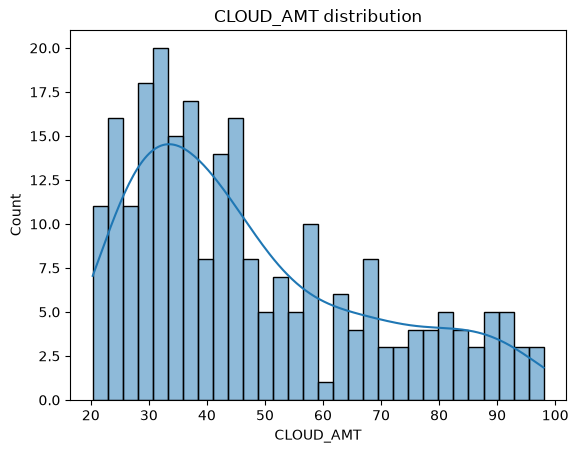

In [21]:
import seaborn as sns
import matplotlib.pyplot as plt
sns.histplot(preprocessing_data["CLOUD_AMT"], bins = 30, kde = True)

preprocessing_data["CLOUD_AMT"].skew()

plt.title("CLOUD_AMT distribution")
plt.show()


In [22]:
preprocessing_data["CLOUD_AMT"].skew()

np.float64(0.8192460293245295)

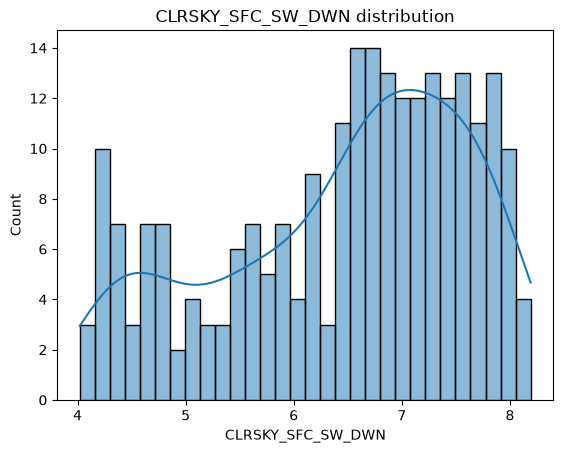

In [12]:
sns.histplot(preprocessing_data["CLRSKY_SFC_SW_DWN"], bins = 30, kde = True)
plt.title("CLRSKY_SFC_SW_DWN distribution")
plt.show()

In [23]:
preprocessing_data["CLRSKY_SFC_SW_DWN"].skew()

np.float64(-0.5831468714528283)

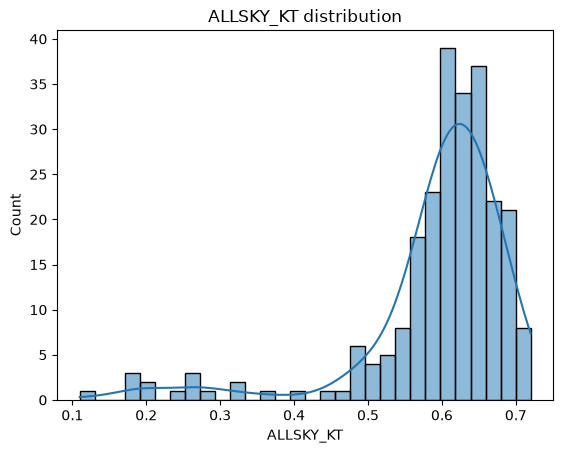

In [13]:
sns.histplot(preprocessing_data["ALLSKY_KT"], bins = 30, kde = True)
plt.title("ALLSKY_KT distribution")
plt.show()

In [24]:
preprocessing_data["ALLSKY_KT"].skew()

np.float64(-2.4912799164899995)

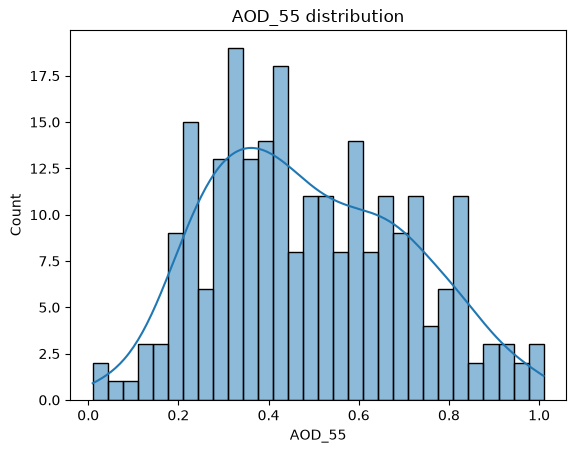

In [20]:
sns.histplot(preprocessing_data["AOD_55"], bins = 30, kde = True)
plt.title("AOD_55 distribution")
plt.show()

In [25]:
preprocessing_data["AOD_55"].skew()

np.float64(0.27312661909856517)

In [30]:
# fill the null values with mean or median
preprocessing_data["AOD_55"] = preprocessing_data["AOD_55"].replace(np.nan, 0.489380)
preprocessing_data["ALLSKY_KT"] = preprocessing_data["ALLSKY_KT"].replace(np.nan, 0.62)
preprocessing_data["CLRSKY_SFC_SW_DWN"] = preprocessing_data["CLRSKY_SFC_SW_DWN"].replace(np.nan, 6.7321)
preprocessing_data["CLOUD_AMT"] = preprocessing_data["CLOUD_AMT"].replace(np.nan, 42.225)

preprocessing_data.isnull().sum()

ALLSKY_SFC_SW_DWN    0
CLRSKY_SFC_SW_DWN    0
ALLSKY_KT            0
CLOUD_AMT            0
AOD_55               0
T2M                  0
T2M_MAX              0
RH2M                 0
WS10M                0
PRECTOTCORR          0
dtype: int64

In [31]:
# check for duplicate rows
preprocessing_data.duplicated().any()

np.False_

In [33]:
# check if every value in the column has consistent datatype
preprocessing_data["T2M"].apply(type).value_counts()

T2M
<class 'float'>    243
Name: count, dtype: int64

<Axes: xlabel='ALLSKY_KT'>

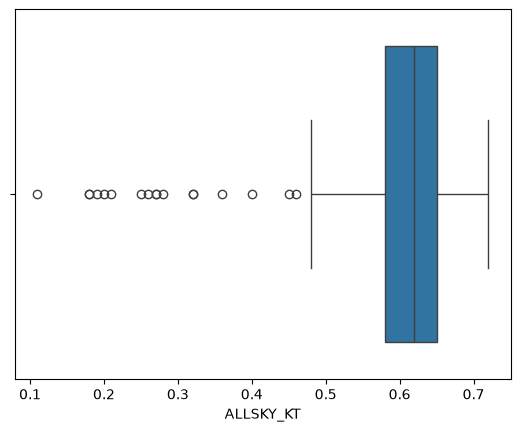

In [35]:
# inspect outliers
sns.boxplot(x = preprocessing_data["ALLSKY_KT"])

In [40]:
q1 = preprocessing_data["ALLSKY_KT"].quantile(0.25)
q3 = preprocessing_data["ALLSKY_KT"].quantile(0.75)

IQR = q3 - q1

lower_bound = q1 - 1.5 * IQR
upper_bound = q3 + 1.5 * IQR

outliers = preprocessing_data.loc[(preprocessing_data["ALLSKY_KT"] < lower_bound) | (preprocessing_data["ALLSKY_KT"] > upper_bound), "ALLSKY_KT"]

print(outliers)

20260125    0.36
20260308    0.45
20260310    0.40
20260312    0.26
20260313    0.46
20260318    0.28
20260320    0.18
20260321    0.32
20260323    0.11
20260324    0.27
20260325    0.21
20260326    0.32
20260327    0.18
20260331    0.19
20260409    0.27
20260411    0.20
20260412    0.25
Name: ALLSKY_KT, dtype: float64


In [ ]:
# check if the values fall within the specifc range of the column